In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import utm

In [ ]:
df = pd.read_parquet("../data/divar_clean.parquet")

<div dir="rtl" align="right">

## آماده‌سازی داده‌ها

ابتدا ردیف‌هایی که در ستون‌های مهم مقدار خالی دارند حذف می‌شوند.  
تعداد اتاق‌ها در داده به صورت متن است و عددی نیستند، به همین دلیل با یک دیکشنری به عدد **تبدیل** شده‌اند (`بدون اتاق` برابر ۰ و `پنج یا بیشتر` برابر ۵).  
سپس مختصات جغرافیایی با کتابخانه `utm` به **UTM** تبدیل شده و در ستون‌های `utm_x` و `utm_y` ذخیره شده است.

</div>

In [ ]:
df = df.dropna(subset=["location_latitude", "location_longitude", "price_value", "building_size", "rooms_count"])

rooms = {
    "بدون اتاق": 0,
    "یک": 1,
    "دو": 2,
    "سه": 3,
    "چهار": 4,
    "پنج یا بیشتر": 5,
}

df["rooms_count"] = df["rooms_count"].map(rooms)
df = df.dropna(subset=["rooms_count"])

utm_x, utm_y = [], []
for lat, lon in zip(df["location_latitude"], df["location_longitude"]):
    x, y, _, _ = utm.from_latlon(lat, lon)
    utm_x.append(x)
    utm_y.append(y)
df["utm_x"] = utm_x
df["utm_y"] = utm_y

features = ["location_latitude", "location_longitude", "price_value", "building_size", "rooms_count"]
X = df[features]
print(df.shape)

(289790, 128)


<div dir="rtl" align="right">

## خوشه‌بندی با KMeans

در این بخش ابتدا داده‌ها با `StandardScaler` **استاندارد** می‌شوند.  
سپس **KMeans** با **۱۰ خوشه** و **۱۰ بار** شروع با نقطه تصادفی (`n_init=10`) اجرا می‌شود.  
خروجی `labels` برای هر ردیف داده یک عدد بین ۰ تا ۹ است که نشان می‌دهد آن ردیف در کدام خوشه قرار دارد.  
در پایان **مرکز خوشه‌ها** به مقیاس اصلی برگردانده می‌شود تا روی نمودار UTM نمایش داده شود.

</div>

In [ ]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=10,n_init=10 ,random_state=44)

utm_x, utm_y = [], []
for lat, lon in zip(df["location_latitude"], df["location_longitude"]):
    x, y, _, _ = utm.from_latlon(lat, lon)
    utm_x.append(x)
    utm_y.append(y)
df["utm_x"] = utm_x
df["utm_y"] = utm_y


labels = kmeans.fit_predict(X_scaled)
df["cluster"] = labels

centers = scaler.inverse_transform(kmeans.cluster_centers_)
center_utm_x = centers[:, 0]
center_utm_y = centers[:, 1]

C:\Users\IT CITY\AppData\Local\Temp\ipykernel_336\438054378.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["cluster"] = labels


<div dir="rtl" align="right">

## نمودار خوشه‌ها

در این نمودار هر نقطه یک ملک است که با توجه به خوشه‌اش رنگ شده و **مرکز هر خوشه** با علامت `X` مشکی نمایش داده شده است.

</div>

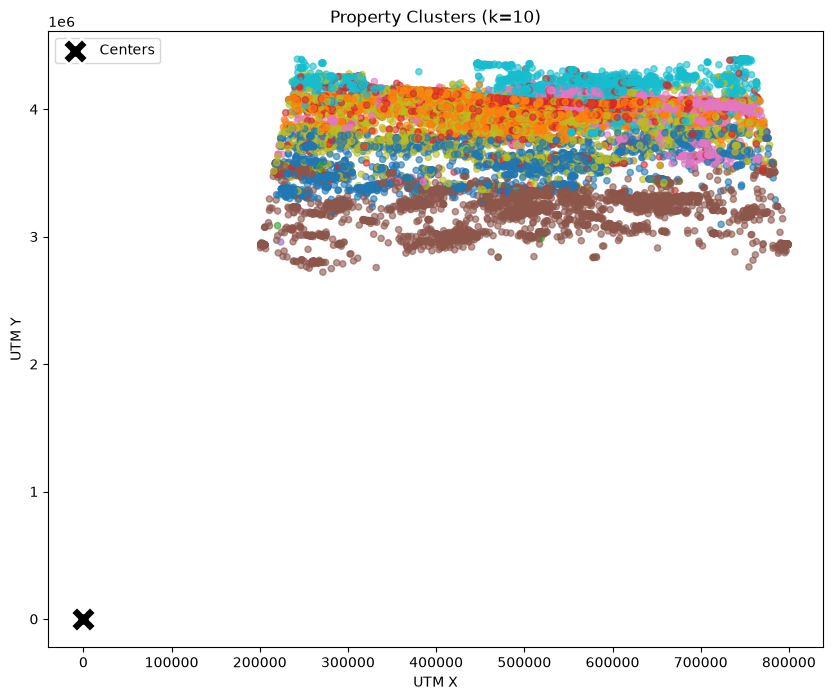

In [ ]:
plt.figure(figsize=(10, 8))
plt.scatter(df["utm_x"], df["utm_y"], c=labels, cmap="tab10", s=20, alpha=0.6)
plt.scatter(center_utm_x, center_utm_y, c="black", marker="X", s=350, edgecolors="white", linewidths=2, label="Centers", zorder=5)
plt.xlabel("UTM X")
plt.ylabel("UTM Y")
plt.title("Property Clusters (k=10)")
plt.legend()
plt.show()

In [12]:
wcss = []
k_range = range(1, 21)

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=44)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

print(wcss)

[1448950.0, 1207397.837298105, 982753.1196032312, 806194.3641171486, 576915.8065563056, 450732.2723293554, 387864.6949410257, 347629.9062033319, 309454.5747055954, 281197.12610089727, 253702.6271496081, 235582.63178408568, 220821.2792062663, 206578.08897246936, 195427.24790567742, 182195.9567316634, 174247.45156336622, 165140.1290101086, 158747.0274729401, 145788.0191157124]


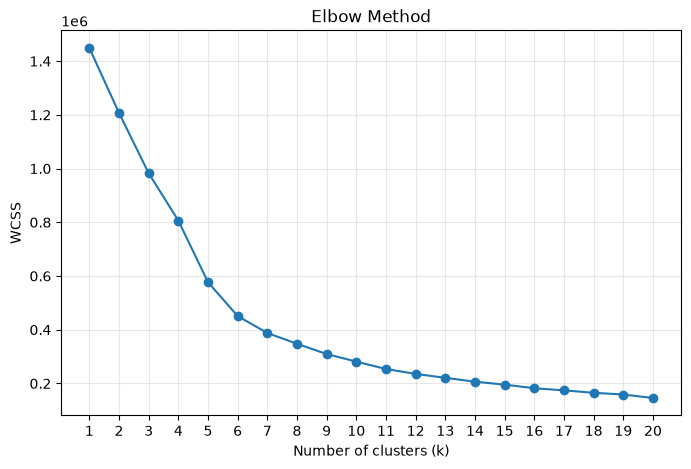

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(list(k_range), wcss, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.xticks(list(k_range))
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sil = silhouette_score(X_scaled, labels)
db = davies_bouldin_score(X_scaled, labels)
ch = calinski_harabasz_score(X_scaled, labels)

print("Silhouette Score:", sil)
print("Davies-Bouldin Index:", db)
print("Calinski-Harabasz Index:", ch)

Silhouette Score: 0.48854769831606154
Davies-Bouldin Index: 0.7285172275844325
Calinski-Harabasz Index: 133710.6966063492


<div dir="rtl" align="right">

## نتیجه معیارهای ارزیابی برای ۱۰ خوشه

- **Silhouette Score:** `0.48854769831606154`
- **Davies-Bouldin Index:** `0.7285172275844325`
- **Calinski-Harabasz Index:** `133710.6966063492`

</div>

In [ ]:
results = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)

    results.append([k, sil, db, ch])

for row in results:
    print(row)

In [ ]:
#[K, Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index]

[2, 0.9779510409595203, 0.2569208120406292, 57975.02361085802]

[3, 0.41975427209610966, 0.8417677960005018, 68734.35081746752]

[4, 0.4240892232221648, 0.7205113735613367, 91118.63991786462]

[5, 0.4791324147836299, 0.681273557660147, 109505.77522425045]

[6, 0.42554047092165154, 0.6868054621139477, 128355.62252939772]

[7, 0.4397088891573724, 0.7286977943324453, 132127.03945575812]

[8, 0.46457733729416184, 0.6611260839774562, 131005.19794752896]

[9, 0.4825715459272108, 0.728682948371841, 133199.87261835937]

[10, 0.4885240025883436, 0.7277330143652969, 133710.42901132346]

<div dir="rtl" align="right">

## مقایسه معیارها برای تعداد خوشه‌های مختلف

هر ردیف از خروجی زیر به صورت
`[K, Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index]`
است و نتیجه‌ی **KMeans** را برای هر مقدار `K` نشان می‌دهد.

</div>

<div dir="rtl" align="right">
[K, Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index]

[2, 0.9779510409595203, 0.2569208120406292, 57975.02361085802]

[3, 0.41975427209610966, 0.8417677960005018, 68734.35081746752]

[4, 0.4240892232221648, 0.7205113735613367, 91118.63991786462]

[5, 0.4791324147836299, 0.681273557660147, 109505.77522425045]

[6, 0.42554047092165154, 0.6868054621139477, 128355.62252939772]

[7, 0.4397088891573724, 0.7286977943324453, 132127.03945575812]

[8, 0.46457733729416184, 0.6611260839774562, 131005.19794752896]

[9, 0.4825715459272108, 0.728682948371841, 133199.87261835937]

[10, 0.4885240025883436, 0.7277330143652969, 133710.42901132346]
</div>

<div dir="rtl" align="right">

## نمودار دقت خوشه‌ها (Elbow)

در این بخش مقدار **WCSS** برای `K` از ۱ تا ۱۰ محاسبه شده و در نمودار رسم می‌شود تا با **روش آرنج** بهترین تعداد خوشه انتخاب شود.

</div>

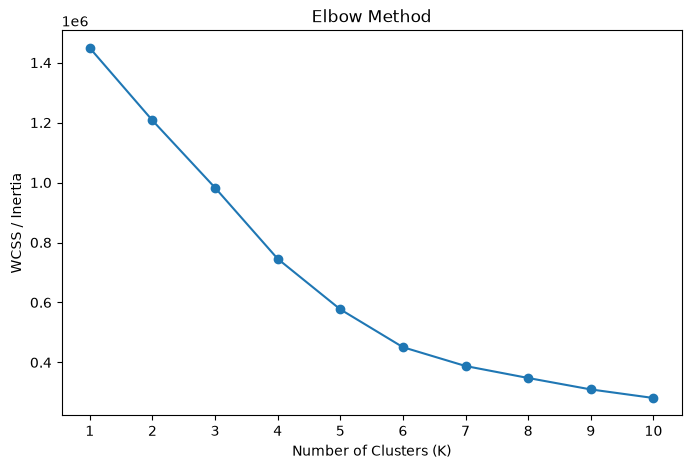

In [ ]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.show()